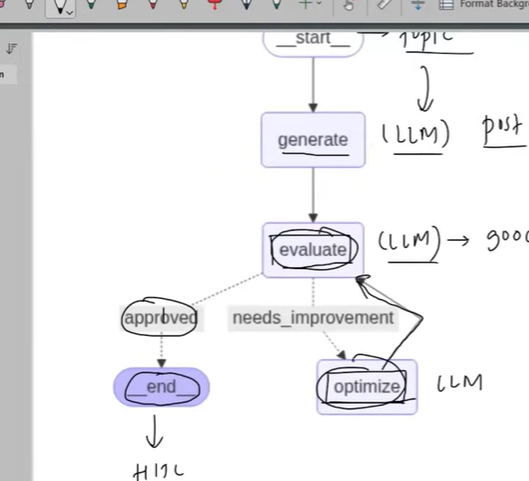

In [21]:
from langgraph.graph import StateGraph , START , END

In [22]:
from ast import And
from groq import Groq

client = Groq(api_key="YOUR_GROQ_API_KEY")

def getResponse(text : str) -> str:
 completion = client.chat.completions.create(
    model="openai/gpt-oss-20b",
    messages=[
      {
        "role": "user",
        "content": text
      }
    ],
    temperature=1,
    max_completion_tokens=8192,
    top_p=1,
    reasoning_effort="medium",
    stream=True,
    stop=None
 )

 response = ""
 for chunk in completion:
    response += chunk.choices[0].delta.content or ""

 return response


In [23]:
response = getResponse("what are the accomplishments of albert einsten")

In [24]:
response

'**Albert\u202fEinstein’s most widely recognized accomplishments**\n\n| Field | Key Contributions | Impact |\n|-------|-------------------|--------|\n| **Special Theory of Relativity (1905)** | • Introduced the postulate that the speed of light is constant for all observers.<br>• Derived the famous mass–energy equivalence, \\(E=mc^2\\). | • Revolutionized our understanding of space, time, and energy. <br>• Lays the foundation for modern physics and nuclear energy. |\n| **Photoelectric Effect (1905)** | • Explained the ejection of electrons from metal surfaces by light using the concept of photons.<br>• Won the Nobel Prize in Physics (1921). | • Provided critical evidence for the quantum nature of light. <br>• Crucial for the development of quantum mechanics and modern electronics. |\n| **Brownian Motion (1905)** | • Offered a statistical explanation for the random motion of pollen grains in water.<br>• Provided evidence for the existence of atoms and molecules. | • Strengthened the emp

In [25]:
from typing import TypedDict , Literal
class TweetState(TypedDict):
    topic : str
    tweet : str
    evaluation : Literal["approved" , "needs_improvement"]
    feedback : str
    iteration : int
    max_iteration : int
    # we will stop the iterative loop once we reach the max iterations



In [26]:
from langchain_core.messages import SystemMessage , HumanMessage
def generate_tweet(state : TweetState) -> TweetState:
    messages = [
        SystemMessage(content = "Ypu are a funny and clever Twitter/X influencer."),
        HumanMessage(content = f"""Write a short , original and hilarious tweet on the topic: "{state['topic']}".
                     
                     Rules:
                     - Do not use question-answer format.
                     - Max 280 characters.
                     - Use observational humor , irony , sarcasm or cultural references.
                     - Think in meme logic , punchlines or relatable takes.
                     - Use simple , day to day english
                     - This is version {state['iteration'] + 1}
                     """)
    ]

    response = getResponse(messages)
    return {'tweet' : response}
    



In [27]:


def evaluate_tweet(state : TweetState) -> TweetState:

    messages = [
        SystemMessage(content = "You are a ruthless , no-laugh-given Twitter critic. You evaluate tweets. "),
        HumanMessage(content = f"""
Evaluate the following tweet:
                     
Tweet : "{state['tweet']}"

use the criteria below to evaluate the tweet :

1. Originality -> Is this fresh , or have you seen it a hundred times before?
2. Humor -> Did it genuinely make you smile , laugh or chuckle?
3. Punchiness -> Is it short , sharpe and scroll-stopping?
4. Virtuality Potential -> Would people retweet or share it?
5. Format -> Is it a well-formed tweet (not a setup-punchline joke , not a Q&A joke and under 280 characters).

Auto-reject if:
- It's written in question-answer format(e.g., "Why did..." or "What happens when...")
- It exceeds 280 characters.
- It reads like a traditional setup-punchline joke.
- Dont end with generic , throwaway , or deflating lines that weaken the humor.

### Respond ONLY in a structured_format STRICTLY!:
- evaluation : "approved" or "needs_improvement"
- feedback : One paragraph explaining the strengths and weaknesses.
""")
    ]

    response = getResponse(messages)

    return {'evaluation' : response['evaluation'] , 'feedback' : response['feedback']}


In [28]:
def optimize_tweet(state : TweetState) -> TweetState :
    messages =[
        SystemMessage(content="You punch up tweets for virality and humor based on given feedback."),
        HumanMessage(content = f"""
Improve the tweet based on this feedback:{state['tweet']}

Topic : "{state['topic']}"
Original Tweet:
{state['tweet']}

Re-write it as short , viral-worthy tweet.Avoid Q&A style and stay under 280 characters.
""")
    ]

    response = getResponse(messages)
    iteration = state['iteration'] + 1

    return {'tweet' : response , 'iteration' : iteration}

In [29]:
def route_evaluation(state : TweetState):
    if state['evaluation'] == 'approved' or state['iteration'] >= state['max_iteration']:
        return 'approved'
    else:
        return 'needs_improvement'

In [30]:
graph = StateGraph(TweetState)

graph.add_node('generate' , generate_tweet)
graph.add_node('evaluate' , evaluate_tweet)
graph.add_node('optimize' , optimize_tweet)

graph.add_edge(START , 'generate')
graph.add_edge('generate' , 'evaluate')
graph.add_conditional_edges('evaluate' , route_evaluation , {'approved' : END , 'needs_improvement' : 'optimize'})
graph.add_edge('optimize' , 'evaluate')


In [31]:
workflow = graph.compile()

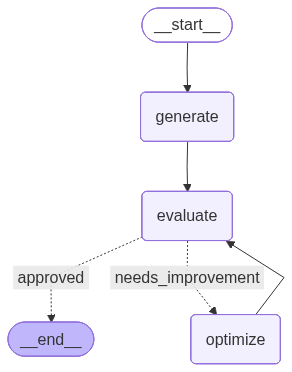

In [32]:
workflow

In [ ]:
initial_state = {
    "topic" : "Indian Railways",
    "iteration" : 1,
    "max_iteration" : 5
}

workflow.invoke(initial_state)

BadRequestError: Error code: 400 - {'error': {'message': "'messages.0' : for 'role:user' the following must be satisfied[('messages.0.content' : one of the following must be satisfied[('messages.0.content' : value must be a string) OR ('messages.0.content.0' : one of the following must be satisfied[('messages.0.content.0.type' : property 'type' is missing) OR ('messages.0.content.0.type' : property 'type' is missing)])])]", 'type': 'invalid_request_error'}}